In [2]:
# Set up and prepare release-year data

import warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
warnings.filterwarnings('ignore')

df = pd.read_csv('Netflix_Cleaned.csv')
yearly = df.groupby('release_year').size().loc[2000:2020]   
yearly.tail(8)

release_year
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
dtype: int64

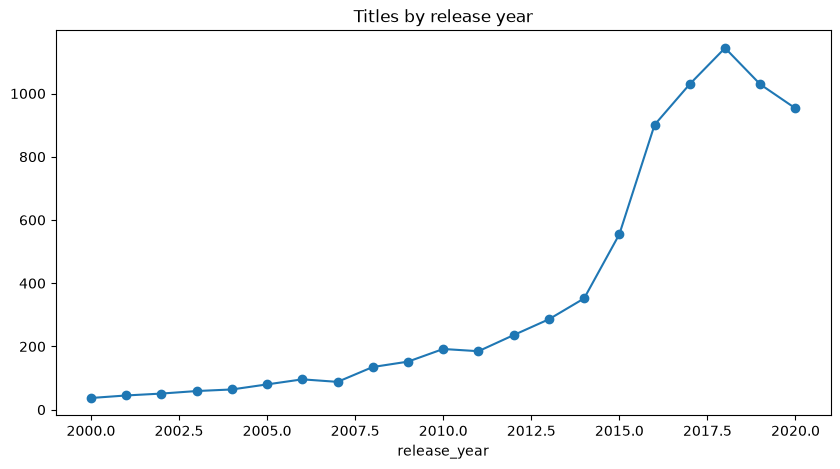

In [3]:
# Analyze yearly content trends

yearly.plot(marker='o', figsize=(10,5), title='Titles by release year'); plt.show()

In [4]:
growth = yearly.pct_change().mul(100).round(1)
print("Peak:", yearly.idxmax(), yearly.max())
growth.tail(6)

Peak: 2018 1144


release_year
2015    57.7
2016    62.3
2017    14.3
2018    11.1
2019   -10.1
2020    -7.4
dtype: float64

In [5]:
# Build forecasting models

train, test = yearly.loc[:2016], yearly.loc[2017:]     # split by time, never randomly
X_tr, X_te = train.index.values.reshape(-1,1), test.index.values.reshape(-1,1)
preds = {}
preds['Linear'] = LinearRegression().fit(X_tr, train.values).predict(X_te)
pf = PolynomialFeatures(2)
preds['Polynomial (deg 2)'] = LinearRegression().fit(pf.fit_transform(X_tr-2000), train.values).predict(pf.transform(X_te-2000))
preds['Holt (damped trend)'] = ExponentialSmoothing(train.values.astype(float), trend='add', damped_trend=True).fit().forecast(len(test))
preds['ARIMA(1,1,1)'] = ARIMA(train.values.astype(float), order=(1,1,1)).fit().forecast(len(test))
preds['Naive (repeat last)'] = np.repeat(train.iloc[-1], len(test))

In [6]:
results = pd.DataFrame([(k, mean_absolute_error(test, v), np.sqrt(mean_squared_error(test, v)))
                        for k, v in preds.items()], columns=['model','MAE','RMSE']).round(1)
results.sort_values('RMSE')

,model,MAE,RMSE
4,Naive (repeat last),138.0,153.9
1,Polynomial (deg 2),183.7,203.5
0,Linear,454.4,464.7
3,"ARIMA(1,1,1)",699.8,802.5
2,Holt (damped trend),718.4,833.9


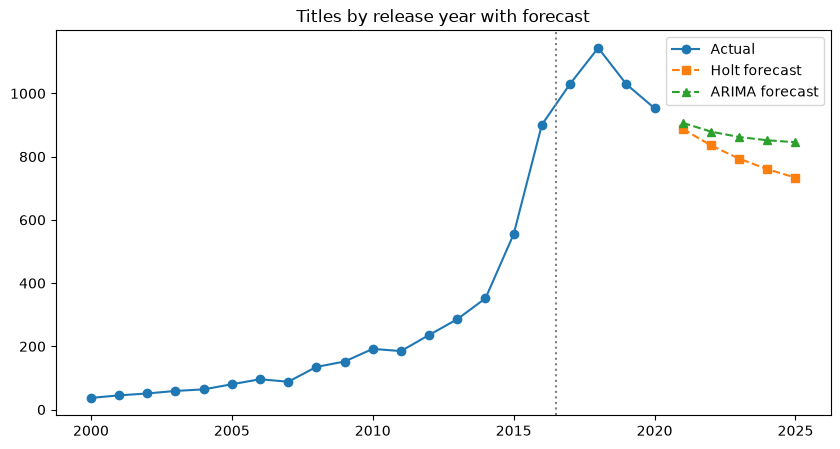

In [7]:
# Visualize future predictions

future = np.arange(2021, 2026)
f_hw = ExponentialSmoothing(yearly.values.astype(float), trend='add', damped_trend=True).fit().forecast(5)
f_ar = ARIMA(yearly.values.astype(float), order=(1,1,1)).fit().forecast(5)

plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly.values, 'o-', label='Actual')
plt.plot(future, f_hw, 's--', label='Holt forecast')
plt.plot(future, f_ar, '^--', label='ARIMA forecast')
plt.axvline(2016.5, color='grey', ls=':')
plt.legend(); plt.title('Titles by release year with forecast'); plt.show()

In [ ]:
# Step 5: Interpret results

Trend: The number of titles by release year grew quickly from 286 in 2013 to a peak of
1144 in 2018. It then fell to 1029 in 2019 and 953 in 2020 (down 10.1% and 7.4%).

Model comparison: I trained 5 models on 2000-2016 and tested them on 2017-2020.
The simple "repeat last year(Naive)" baseline had the lowest error(RMSE about 153.9),followed by
Polynomial (about 203.5), Linear (about 464.7), ARIMA (about 802.5) and Holt (about 833.9).
The more complex models did worst because they were trained during a period of fast growth
and kept projecting it, but the trend changed after 2018.


Forecast: Fitting Holt and ARIMA on all the data, both expect the yearly count to level
off or decline slightly from 2021 to 2025: Holt goes from about 888 to 734, and ARIMA from
about 907 to 846. Neither expects a return to the rapid growth seen before 2018.

Limitations: The fall in 2019–2020 may partly be due to COVID slowing production.
The dataset only includes titles that were on Netflix in 2021, so recent years are not a
full count of what was produced.
With about 20 yearly data points, forecasts five years ahead are rough estimates, not
exact predictions.

Conclusion: No forecasting model beat the simple baseline on the test years, because
the trend changed direction after the training period. The forecasts should therefore be
treated with caution, and a longer time series or extra information would be needed for
more reliable predictions.